# Clusterização de imagens de glaucoma (HYGD): versão de apresentação

**Objetivo:** agrupar as imagens de fundo de olho **sem usar nenhum rótulo** e comparar três formas de descrever cada imagem:

1. **Tradicional:** 37 estatísticas calculadas direto nos pixels (cor, histogramas, nitidez, iluminação).
2. **Deep Learning:** 1024 números (*embedding*) da última camada escondida da MobileNetV3-Small, pré-treinada e congelada.
3. **Híbrida:** as duas juntas, com o mesmo peso.

**Regra do projeto:** `Label` (GON+/GON-), `Quality Score`, ID do paciente, formato e largura da imagem **não entram** no K-Means. Só servem depois, para interpretar os clusters.

**Pergunta central:** os clusters refletem características úteis das imagens ou vieses de qualidade e origem? Eles **não** são diagnósticos nem estágios de glaucoma.

> Esta é a versão resumida do `clusterizacao.ipynb`. O notebook completo tem ainda: o roteador por centroides, os testes com EfficientNet-B0 e ResNet18, o efeito do peso na abordagem híbrida e a coesão por paciente.

## 1. Configuração

- **Semente 42** em tudo e PyTorch na **CPU**: na CPU o resultado não muda com o tamanho do lote.
- `USAR_CACHE = True` reaproveita os embeddings e as características salvos pelo notebook completo em `outputs/`. Se eles não existirem, tudo é calculado aqui (cerca de 2 minutos).

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from scipy import ndimage as ndi
from matplotlib.colors import rgb_to_hsv
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path.cwd()                      # executar a partir da raiz do projeto
IMAGES_DIR = ROOT / "data" / "Images"
OUT_DIR = ROOT / "outputs"
DEVICE = torch.device("cpu")
USAR_CACHE = True

plt.rcParams.update({"figure.dpi": 100, "grid.alpha": 0.3})

## 2. Dados

A análise exploratória (`analise-exploratoria.ipynb`, que deve ser executada antes) encontrou:
- **10 arquivos que são cópias exatas** de outros, 6 deles com IDs de paciente diferentes. Removemos as cópias (**747 → 737 imagens**) e tratamos IDs ligados por uma cópia como o mesmo paciente (**283 grupos**).
- **O ID do paciente é uma cópia do diagnóstico:** GON+ têm ID de 0 a 186; GON- de 187 a 288. Por isso o ID nunca entra como característica.
- **11 arquivos são PNG** com extensão `.jpg`, todos GON-: sinal de origem diferente.

Imagens do mesmo paciente são parecidas, então testes e sorteios são feitos **por paciente**, não por imagem.

In [2]:
df = pd.read_csv(ROOT / "data" / "Labels.csv").dropna(axis=1, how="all")
auditoria = pd.read_csv(OUT_DIR / "auditoria_duplicatas.csv")
assert auditoria["Image Name"].tolist() == df["Image Name"].tolist(), "Execute antes o analise-exploratoria.ipynb."
copias = auditoria["copia_de_outra"].to_numpy(dtype=bool)
df = df.assign(Grupo=auditoria["grupo_paciente"].to_numpy())[~copias].reset_index(drop=True)

nomes = df["Image Name"].tolist()
caminhos = [IMAGES_DIR / n for n in nomes]
formatos, larguras = [], []
for c in caminhos:
    with Image.open(c) as im:
        formatos.append(im.format)
        larguras.append(im.width)

meta = df.assign(Format=formatos, Width=larguras)
meta["y_pos"] = (meta["Label"] == "GON+").astype(int)
meta["is_png"] = (meta["Format"] == "PNG").astype(int)

IDS_PAC, IDX_PAC = np.unique(meta["Grupo"].to_numpy(), return_inverse=True)   # índices por paciente (grupo)
N_PAC = len(IDS_PAC)
Y = meta["y_pos"].to_numpy()
QUALIDADE = meta["Quality Score"].to_numpy()

print(f"Cópias removidas: {int(copias.sum())} | Imagens: {len(meta)} | Pacientes (grupos): {N_PAC} | "
      f"GON+: {Y.sum()} ({100 * Y.mean():.1f}%)")
print("\nID do paciente por diagnóstico:")
display(meta.drop_duplicates("Patient").groupby("Label")["Patient"].agg(["min", "max", "count"]))
print("Formato real do arquivo por diagnóstico:")
display(pd.crosstab(meta["Format"], meta["Label"]))

Cópias removidas: 10 | Imagens: 737 | Pacientes (grupos): 283 | GON+: 540 (73.3%)

ID do paciente por diagnóstico:


,min,max,count
Label,,,
GON+,0,186,185
GON-,187,288,101


Formato real do arquivo por diagnóstico:


Label,GON+,GON-
Format,,
JPEG,540,186
PNG,0,11


## 3. De imagem para números

### Deep Learning: MobileNetV3-Small
- **Por que ela:** é a mais leve das redes testadas (2,5 M de parâmetros, ~20 s na CPU) e tem uma camada densa escondida explícita (576 → 1024) antes da classificação.
- **Pesos congelados:** nada é treinado. Com 737 imagens, uma rede treinada aprenderia atalhos (brilho, borda preta).
- **Como pegamos o embedding:** um *hook* guarda a **entrada da última camada linear**, ou seja, as 1024 ativações da última camada escondida. A saída de 1000 classes do ImageNet nunca é usada.
- **Pré-processamento:** redimensionar para 224 × 224 (as imagens são quadradas, não há distorção) e normalizar com a média e o desvio do ImageNet. **Sem CLAHE nem recorte:** o CLAHE nivelaria brilho e contraste, justamente os sinais de qualidade que queremos detectar.

### Tradicional: 37 estatísticas
- Cor (média e desvio de R, G, B e saturação), histogramas de 8 faixas por canal, nitidez (Laplaciano, gradiente de Sobel), entropia e iluminação (uniformidade entre blocos e fração escura).
- Calculadas **só dentro do campo de visão** (a máscara exclui a borda preta) e com as imagens reduzidas para 512 × 512, para que a nitidez seja comparável.

In [3]:
def abrir_rgb(caminho):
    with Image.open(caminho) as imagem:
        return imagem.convert("RGB")


# --- Deep Learning
pesos = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
rede = models.mobilenet_v3_small(weights=pesos, progress=False).to(DEVICE).eval()
for parametro in rede.parameters():
    parametro.requires_grad = False                     # pesos congelados

preprocessar = transforms.Compose([
    transforms.Resize((224, 224), interpolation=InterpolationMode.BILINEAR, antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(mean=pesos.transforms().mean, std=pesos.transforms().std),
])

capturado = {}
rede.classifier[3].register_forward_pre_hook(          # entrada da última camada linear = embedding de 1024
    lambda modulo, entradas: capturado.update(embedding=entradas[0].detach().cpu()))


def extrair_embeddings(lista, lote=32):
    saida = []
    for i in range(0, len(lista), lote):
        x = torch.stack([preprocessar(abrir_rgb(c)) for c in lista[i:i + lote]]).to(DEVICE)
        with torch.no_grad():
            rede(x)
        saida.append(capturado["embedding"].numpy().copy())
    return np.concatenate(saida)


# --- Tradicional
LADO_TRAD, LIMIAR_FOV = 512, 15 / 255
LUMINANCIA = np.array([0.299, 0.587, 0.114], dtype=np.float32)
COLUNAS_TRAD = ([f"{c}_{s}" for c in "RGB" for s in ("media", "desvio")] + ["S_media", "S_desvio"]
                + [f"hist_{c}_{f}" for c in "RGB" for f in range(8)]
                + ["entropia_cinza", "laplaciano_var", "gradiente_medio", "uniformidade_ilum", "fracao_escura"])


def mascara_fov(rgb):
    # Campo de visão: maior região com pixels acima do limiar, sem buracos
    bruto = ndi.binary_opening(rgb.max(axis=2) > LIMIAR_FOV, iterations=3)
    rotulos, n = ndi.label(bruto)
    if n == 0:
        return bruto
    tamanhos = ndi.sum(bruto, rotulos, range(1, n + 1))
    return ndi.binary_fill_holes(rotulos == (1 + int(np.argmax(tamanhos))))


def caracteristicas_tradicionais(caminho):
    with Image.open(caminho) as imagem:
        rgb = np.asarray(imagem.convert("RGB").resize((LADO_TRAD, LADO_TRAD), Image.Resampling.BILINEAR),
                         dtype=np.float32) / 255.0
    m = mascara_fov(rgb)
    f = {}
    for i, canal in enumerate("RGB"):
        f[f"{canal}_media"], f[f"{canal}_desvio"] = rgb[..., i][m].mean(), rgb[..., i][m].std()
    hsv = rgb_to_hsv(rgb)
    f["S_media"], f["S_desvio"] = hsv[..., 1][m].mean(), hsv[..., 1][m].std()
    for i, canal in enumerate("RGB"):
        contagem, _ = np.histogram(rgb[..., i][m], bins=8, range=(0, 1))
        for faixa, proporcao in enumerate(contagem / contagem.sum()):
            f[f"hist_{canal}_{faixa}"] = proporcao
    cinza = rgb @ LUMINANCIA
    contagem, _ = np.histogram(cinza[m], bins=32, range=(0, 1))
    p = contagem[contagem > 0] / contagem.sum()
    f["entropia_cinza"] = float(-(p * np.log2(p)).sum())
    interior = ndi.binary_erosion(m, iterations=8)     # longe da borda do campo de visão
    f["laplaciano_var"] = float(ndi.laplace(cinza)[interior].var())
    f["gradiente_medio"] = float(np.hypot(ndi.sobel(cinza, axis=1), ndi.sobel(cinza, axis=0))[interior].mean())
    lado, medias = LADO_TRAD // 4, []
    for a in range(4):
        for b in range(4):
            bloco = (slice(a * lado, (a + 1) * lado), slice(b * lado, (b + 1) * lado))
            if m[bloco].mean() >= 0.5:
                medias.append(cinza[bloco][m[bloco]].mean())
    f["uniformidade_ilum"] = float(np.std(medias) / np.mean(medias))
    f["fracao_escura"] = float((hsv[..., 2][m] < 0.2).mean())
    return f


# --- Usa o cache do notebook completo se ele corresponder às mesmas imagens, na mesma ordem
arquivos_cache = [OUT_DIR / "embeddings_mobilenetv3small_1024.npy", OUT_DIR / "caracteristicas_tradicionais.npy",
                  OUT_DIR / "ordem_das_imagens.csv"]
usar_cache = (USAR_CACHE and all(a.exists() for a in arquivos_cache)
              and pd.read_csv(arquivos_cache[2])["Image Name"].tolist() == nomes)

t0 = time.time()
if usar_cache:
    X_dl_bruto = np.load(arquivos_cache[0])
    X_trad = np.load(arquivos_cache[1])
else:
    X_dl_bruto = extrair_embeddings(caminhos)
    linhas = [caracteristicas_tradicionais(c) for c in caminhos]
    X_trad = pd.DataFrame(linhas)[COLUNAS_TRAD].to_numpy()
print(f"{'Carregado do cache' if usar_cache else 'Calculado'} em {time.time() - t0:.0f} s")

X_trad_df = pd.DataFrame(X_trad, columns=COLUNAS_TRAD)
meta["brilho_R"] = X_trad_df["R_media"].to_numpy()          # só para interpretar
meta["nitidez"] = X_trad_df["gradiente_medio"].to_numpy()   # só para interpretar

X_dl = X_dl_bruto[:, X_dl_bruto.std(axis=0) > 1e-6].astype(np.float64)   # remove 2 colunas sem variação
X_trad = X_trad.astype(np.float64)
print(f"Matriz Tradicional: {X_trad.shape} | Matriz Deep Learning: {X_dl.shape}")

Carregado do cache em 0 s
Matriz Tradicional: (737, 37) | Matriz Deep Learning: (737, 1022)


## 4. Padronização, PCA e abordagem híbrida

- **Padronização (z-score):** o K-Means usa distância euclidiana. Sem padronizar, colunas de escala grande decidiriam sozinhas. Cada coluna fica com média 0 e desvio 1.
- **PCA com 90% da variância:** remove redundância e ruído (há 1022 colunas de embedding para 737 imagens).
- **Híbrida:** cada bloco é padronizado e dividido pela **raiz do seu número de colunas**. Assim os dois blocos têm a mesma variância total, e as 1022 colunas do embedding não engolem as 37 tradicionais.

In [4]:
ABORDAGENS = ["Tradicional", "Deep Learning", "Híbrida"]


def matriz_padronizada(abordagem, idx=None):
    idx = np.arange(len(meta)) if idx is None else np.asarray(idx)
    blocos = []
    if abordagem in ("Tradicional", "Híbrida"):
        Zt = StandardScaler().fit_transform(X_trad[idx])
        blocos.append(Zt / np.sqrt(Zt.shape[1]) if abordagem == "Híbrida" else Zt)
    if abordagem in ("Deep Learning", "Híbrida"):
        Zd = StandardScaler().fit_transform(X_dl[idx])
        blocos.append(Zd / np.sqrt(Zd.shape[1]) if abordagem == "Híbrida" else Zd)
    return np.hstack(blocos)


def construir_P(abordagem, idx=None):
    return PCA(n_components=0.90, svd_solver="full", random_state=SEED).fit_transform(matriz_padronizada(abordagem, idx))


P = {ab: construir_P(ab) for ab in ABORDAGENS}
display(pd.DataFrame({
    "colunas originais": [X_trad.shape[1], X_dl.shape[1], X_trad.shape[1] + X_dl.shape[1]],
    "componentes PCA (90%)": [P[ab].shape[1] for ab in ABORDAGENS],
}, index=ABORDAGENS))

,colunas originais,componentes PCA (90%)
Tradicional,37,11
Deep Learning,1022,137
Híbrida,1059,81


> **Leitura:** as 37 estatísticas tradicionais são muito redundantes (quase tudo varia junto com o brilho), e 11 componentes bastam. No Deep Learning a informação é espalhada (137 componentes): nenhuma direção domina, o que já antecipa grupos pouco nítidos.

## 5. K-Means com K de 2 a 10 e as métricas internas

O K-Means escolhe K centros, põe cada imagem no centro mais próximo, move os centros para a média dos seus membros e repete. Usamos `n_init = 20` (20 inícios, fica o melhor) e `random_state = 42`. Os clusters são renumerados por tamanho (C0 = o maior).

| Métrica | O que mede | Melhor |
|---|---|---|
| Inércia (*elbow*) | distância ao quadrado de cada imagem ao seu centro | procurar um "cotovelo" |
| Silhouette | quanto cada imagem está mais perto do seu cluster que do vizinho (−1 a 1) | maior; < 0,25 = estrutura fraca |
| Davies-Bouldin | dispersão interna / distância entre clusters | menor |
| Calinski-Harabasz | dispersão entre clusters / dispersão interna | maior |

**Cuidado:** os valores absolutos não são comparáveis entre abordagens (os espaços têm 11, 137 e 81 dimensões). Comparamos o formato das curvas.

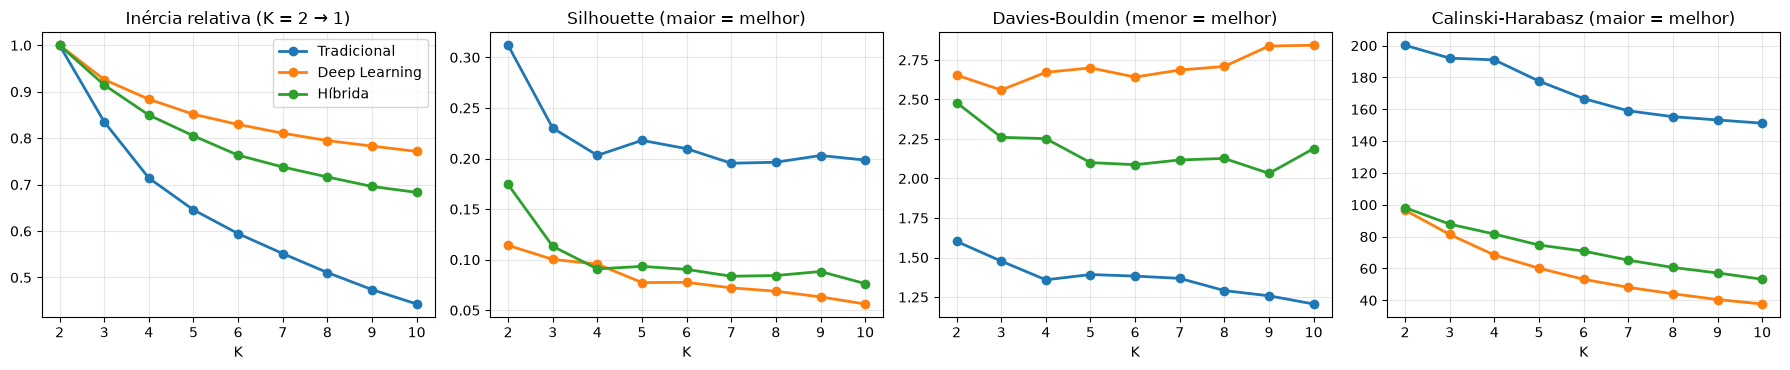

K,2,3,4,5,6,7,8,9,10
silhouette,,,,,,,,,
Tradicional,0.312,0.230,0.203,0.218,0.210,0.195,0.196,0.203,0.198
Deep Learning,0.114,0.100,0.096,0.077,0.078,0.072,0.069,0.063,0.056
Híbrida,0.174,0.113,0.091,0.093,0.090,0.084,0.084,0.088,0.076


In [5]:
KS = list(range(2, 11))


def ordenar_por_tamanho(rotulos):
    ordem = np.argsort(-np.bincount(rotulos), kind="stable")
    mapa = np.empty_like(ordem)
    mapa[ordem] = np.arange(len(ordem))
    return mapa[rotulos]


METRICAS, ROTULOS = {}, {}
for ab in ABORDAGENS:
    linhas, ROTULOS[ab] = [], {}
    for k in KS:
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(P[ab])
        l = ordenar_por_tamanho(km.labels_)
        ROTULOS[ab][k] = l
        linhas.append({"K": k, "inércia": km.inertia_, "silhouette": silhouette_score(P[ab], l),
                       "davies_bouldin": davies_bouldin_score(P[ab], l),
                       "calinski_harabasz": calinski_harabasz_score(P[ab], l)})
    METRICAS[ab] = pd.DataFrame(linhas).set_index("K")

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
titulos = {"inércia": "Inércia relativa (K = 2 → 1)", "silhouette": "Silhouette (maior = melhor)",
           "davies_bouldin": "Davies-Bouldin (menor = melhor)", "calinski_harabasz": "Calinski-Harabasz (maior = melhor)"}
for ax, (coluna, titulo) in zip(axes, titulos.items()):
    for ab in ABORDAGENS:
        valores = METRICAS[ab][coluna]
        ax.plot(KS, valores / valores.iloc[0] if coluna == "inércia" else valores, "o-", lw=2, label=ab)
    ax.set_title(titulo)
    ax.set_xlabel("K")
    ax.set_xticks(KS)
    ax.grid(True)
axes[0].legend()
plt.tight_layout()
plt.show()

display(pd.concat({ab: METRICAS[ab]["silhouette"] for ab in ABORDAGENS}, axis=1).T.round(3).rename_axis("silhouette"))

> **Leitura:** nenhuma métrica aponta um K claramente melhor.
> - A inércia cai de forma gradual, **sem cotovelo**.
> - A silhouette é baixa em tudo: Tradicional 0,31 em K = 2 e ≈ 0,20 depois; Híbrida ≈ 0,09; Deep Learning nunca passa de 0,11. Abaixo de ≈ 0,25 a estrutura é fraca: **as imagens formam um contínuo, não ilhas**.
>
> Então o K vem de outro critério: a estabilidade.

## 6. Estabilidade e escolha do K

**Estabilidade:** sorteamos 80% dos **pacientes**, ajustamos o K-Means nessa parte e classificamos todas as imagens. Repetimos 10 vezes e medimos o **ARI** médio entre os resultados (1 = iguais, 0 = sem relação).

**Regra (não usa rótulo):** o K entre 3 e 6 com a maior estabilidade. K = 2 fica de fora porque é fácil de ler, sem base, como "doente x saudável".

Depois de escolher o K, medimos, **só para interpretar**:
- **NMI com o diagnóstico** (0 = nada, 1 = idêntico), com valor de p por permutação **por paciente** (500 embaralhamentos; o menor p possível é ≈ 0,002);
- **η² da qualidade:** fração da variação do `Quality Score` explicada pelos clusters.

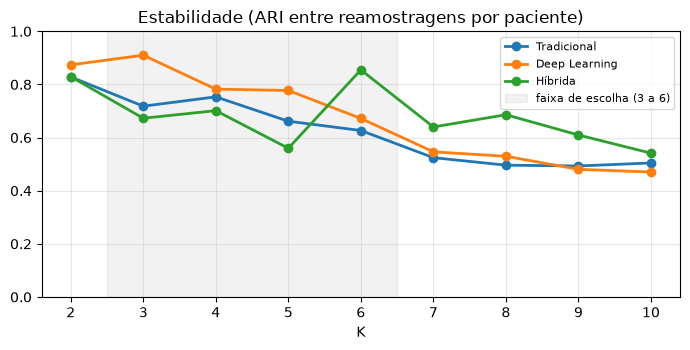

,K,estabilidade,silhouette,tamanhos,NMI diagnóstico,p,η² qualidade
abordagem,,,,,,,
Tradicional,4,0.753,0.203,"[304, 221, 200, 12]",0.008,0.070,0.053
Deep Learning,3,0.910,0.100,"[296, 256, 185]",0.367,0.002,0.325
Híbrida,6,0.855,0.090,"[207, 161, 159, 119, 77, 14]",0.087,0.002,0.201


In [6]:
def estabilidade(Z, k, repeticoes=10, fracao=0.8):
    rng = np.random.default_rng(SEED)
    previsoes = []
    for r in range(repeticoes):
        sorteados = rng.choice(IDS_PAC, size=int(round(fracao * N_PAC)), replace=False)
        usar = np.isin(meta["Grupo"].to_numpy(), sorteados)
        previsoes.append(KMeans(n_clusters=k, n_init=10, random_state=SEED + r).fit(Z[usar]).predict(Z))
    return float(np.mean([adjusted_rand_score(previsoes[i], previsoes[j])
                          for i in range(repeticoes) for j in range(i + 1, repeticoes)]))


# Nulos do NMI: embaralha o diagnóstico ENTRE pacientes (cada paciente mantém um único rótulo)
rotulo_por_paciente = meta.drop_duplicates("Grupo").set_index("Grupo")["y_pos"].reindex(IDS_PAC).to_numpy()
rng_nulo = np.random.default_rng(SEED)
NULOS_Y = np.stack([rng_nulo.permutation(rotulo_por_paciente)[IDX_PAC] for _ in range(500)])


def nmi_com_p(l):
    observado = normalized_mutual_info_score(Y, l)
    nulo = np.array([normalized_mutual_info_score(y, l) for y in NULOS_Y])
    return observado, (1 + np.sum(nulo >= observado)) / (len(NULOS_Y) + 1)


def eta_quadrado(valores, l):
    v = np.asarray(valores, dtype=float)
    entre = sum((l == c).sum() * (v[l == c].mean() - v.mean()) ** 2 for c in np.unique(l))
    return entre / ((v - v.mean()) ** 2).sum()


ESTAB = {ab: {k: estabilidade(P[ab], k) for k in KS} for ab in ABORDAGENS}
K_ESCOLHIDO = {ab: max([3, 4, 5, 6], key=lambda k: ESTAB[ab][k]) for ab in ABORDAGENS}

fig, ax = plt.subplots(figsize=(7, 3.6))
for ab in ABORDAGENS:
    ax.plot(KS, [ESTAB[ab][k] for k in KS], "o-", lw=2, label=ab)
ax.axvspan(2.5, 6.5, color="gray", alpha=0.1, label="faixa de escolha (3 a 6)")
ax.set_title("Estabilidade (ARI entre reamostragens por paciente)")
ax.set_xlabel("K")
ax.set_xticks(KS)
ax.set_ylim(0, 1)
ax.grid(True)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

linhas = []
for ab in ABORDAGENS:
    k = K_ESCOLHIDO[ab]
    l = ROTULOS[ab][k]
    nmi, p = nmi_com_p(l)
    linhas.append({"abordagem": ab, "K": k, "estabilidade": ESTAB[ab][k],
                   "silhouette": METRICAS[ab].loc[k, "silhouette"], "tamanhos": np.bincount(l).tolist(),
                   "NMI diagnóstico": nmi, "p": p, "η² qualidade": eta_quadrado(QUALIDADE, l)})
RESUMO = pd.DataFrame(linhas).set_index("abordagem")
display(RESUMO.round(3))

> **Leitura:**
> - **Tradicional, K = 4** (estabilidade 0,75): um dos clusters tem só 12 imagens. NMI com o diagnóstico ≈ 0.
> - **Deep Learning, K = 3** (0,91): o mais estável e o único com relação clara com o diagnóstico (NMI 0,37, p = 0,002). Também o que mais acompanha a qualidade (η² 0,33).
> - **Híbrida, K = 6** (0,86): a estabilidade oscila muito entre os K, sinal de que ela fica "entre" as outras duas.
>
> Estabilidade alta quer dizer que a divisão é **reprodutível**, não que ela seja clinicamente significativa.

## 7. O que os clusters representam?

Para cada abordagem, no K escolhido: tamanho, composição GON+/GON-, qualidade, brilho, nitidez, largura e número de PNG. A última linha (`todas`) é a referência.

In [7]:
def perfil_clusters(l):
    d = meta.assign(cluster=l)
    tabela = d.groupby("cluster").agg(n=("y_pos", "size"), pacientes=("Grupo", "nunique"), n_GON_pos=("y_pos", "sum"),
                                      qualidade=("Quality Score", "mean"), brilho_R=("brilho_R", "mean"),
                                      nitidez=("nitidez", "mean"), largura=("Width", "mean"), n_PNG=("is_png", "sum"))
    tabela.loc["todas"] = [len(d), d["Grupo"].nunique(), d["y_pos"].sum(), d["Quality Score"].mean(),
                           d["brilho_R"].mean(), d["nitidez"].mean(), d["Width"].mean(), d["is_png"].sum()]
    tabela.insert(3, "%GON+", 100 * tabela["n_GON_pos"] / tabela["n"])
    return tabela.round({"%GON+": 1, "qualidade": 2, "brilho_R": 3, "nitidez": 4, "largura": 0})


for ab in ABORDAGENS:
    k = K_ESCOLHIDO[ab]
    l = ROTULOS[ab][k]
    print(f"=== {ab.upper()} | K = {k} | NMI diagnóstico = {RESUMO.loc[ab, 'NMI diagnóstico']:.3f} | "
          f"η² brilho = {eta_quadrado(meta['brilho_R'], l):.2f} | η² nitidez = {eta_quadrado(meta['nitidez'], l):.2f} | "
          f"η² qualidade = {eta_quadrado(QUALIDADE, l):.2f} ===")
    display(perfil_clusters(l))

=== TRADICIONAL | K = 4 | NMI diagnóstico = 0.008 | η² brilho = 0.56 | η² nitidez = 0.51 | η² qualidade = 0.05 ===


,n,pacientes,n_GON_pos,%GON+,qualidade,brilho_R,nitidez,largura,n_PNG
cluster,,,,,,,,,
0,304,173,204,67.1,6.02,0.447,0.0290,1895.0,8
1,221,133,171,77.4,5.60,0.322,0.0255,1892.0,3
2,200,120,155,77.5,6.09,0.526,0.0388,1911.0,0
3,12,12,10,83.3,5.11,0.570,0.0562,1937.0,0
todas,737,283,540,73.3,5.90,0.433,0.0310,1899.0,11


=== DEEP LEARNING | K = 3 | NMI diagnóstico = 0.367 | η² brilho = 0.13 | η² nitidez = 0.06 | η² qualidade = 0.33 ===


,n,pacientes,n_GON_pos,%GON+,qualidade,brilho_R,nitidez,largura,n_PNG
cluster,,,,,,,,,
0,296,156,272,91.9,5.21,0.387,0.0285,1902.0,0
1,256,118,244,95.3,6.48,0.471,0.0333,1902.0,0
2,185,109,24,13.0,6.19,0.456,0.0319,1891.0,11
todas,737,283,540,73.3,5.90,0.433,0.0310,1899.0,11


=== HÍBRIDA | K = 6 | NMI diagnóstico = 0.087 | η² brilho = 0.65 | η² nitidez = 0.57 | η² qualidade = 0.20 ===


,n,pacientes,n_GON_pos,%GON+,qualidade,brilho_R,nitidez,largura,n_PNG
cluster,,,,,,,,,
0,207,134,94,45.4,5.80,0.439,0.0287,1893.0,9
1,161,102,123,76.4,5.42,0.305,0.0245,1891.0,2
2,159,82,152,95.6,6.56,0.458,0.0308,1897.0,0
3,119,85,103,86.6,5.55,0.431,0.0324,1911.0,0
4,77,48,56,72.7,6.43,0.617,0.0449,1914.0,0
5,14,14,12,85.7,5.31,0.551,0.0553,1934.0,0
todas,737,283,540,73.3,5.90,0.433,0.0310,1899.0,11


> **Leitura:**
> - **Tradicional:** os clusters vão do mais escuro (C1, brilho 0,32) ao mais claro (C2, 0,53), mais um grupinho de 12 imagens extremas (C3). Brilho (η² 0,56) e nitidez (0,51) explicam a divisão; o diagnóstico não (todos os clusters têm 67–83% GON+, perto dos 73% gerais). **Clusters de condição de captura.**
> - **Deep Learning:** C0 e C1 são quase só GON+ e se separam por **qualidade** (5,21 contra 6,48). C2 tem só 13% GON+: reúne 161 dos 197 GON- **e todos os 11 PNG**.
> - **Híbrida:** mistura as duas coisas. Alguns clusters seguem brilho (C1 escuro, C4 claro), outros seguem o diagnóstico (C0 com 113 dos 197 GON-; C2 com 96% GON+).
>
> **Cuidado com o C2 do Deep Learning:** GON- também têm outra origem (ID, PNG, largura mais uniforme). A rede pode estar reconhecendo **a origem das imagens**, não a doença. Com estes dados não dá para separar as duas explicações.

### Como as imagens de cada cluster do Deep Learning se parecem

Por cluster: as 5 imagens mais típicas (mais perto do centro) e 5 sorteadas, sempre de pacientes diferentes. As sorteadas evitam ver só os casos mais "bonitos".

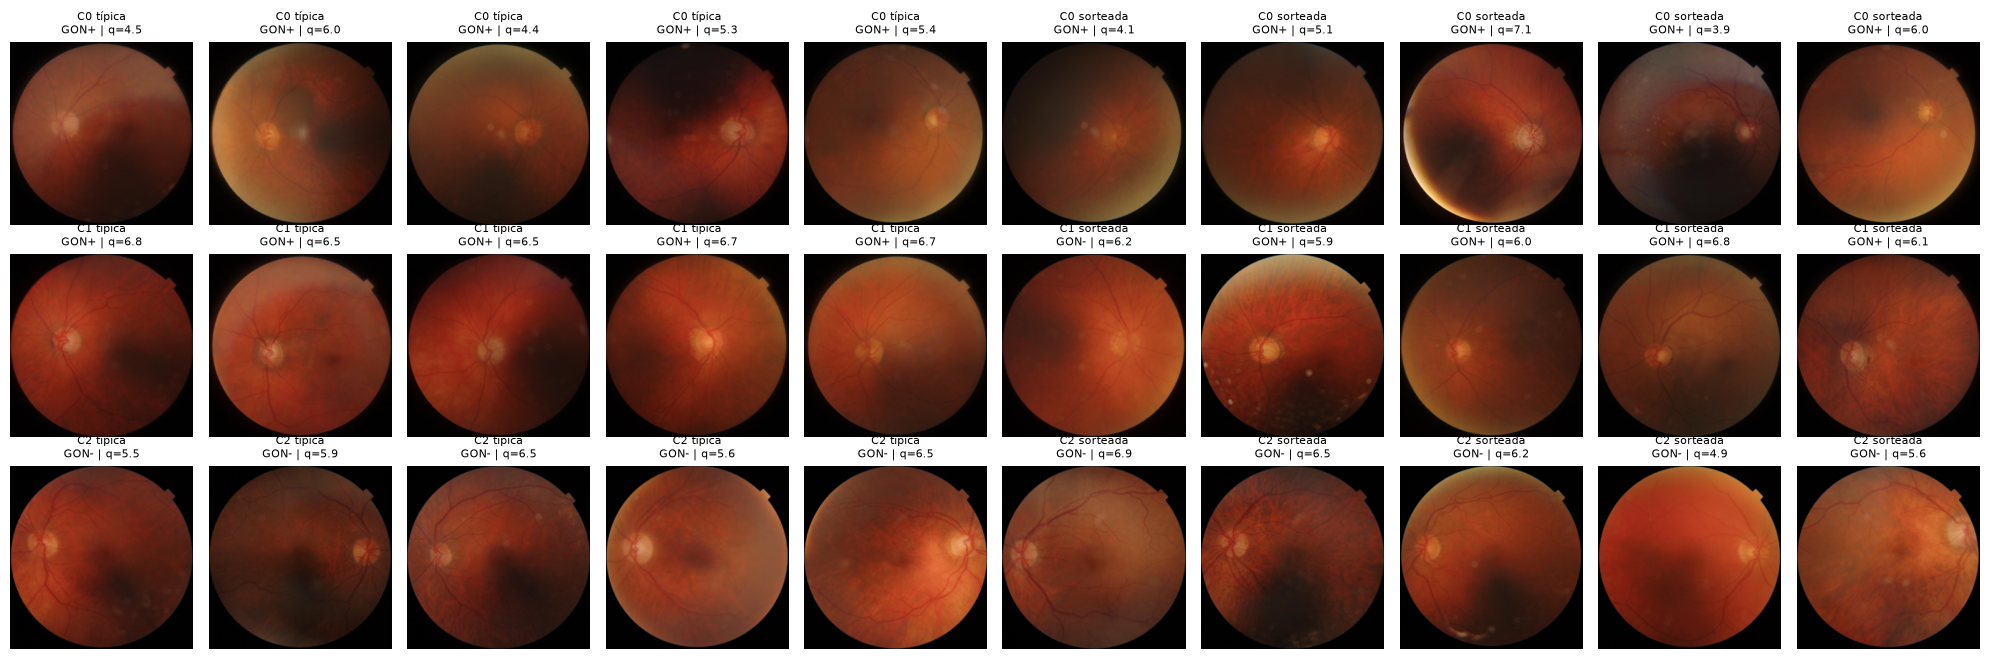

In [8]:
def montagem(Z, l, k, n=5):
    rng = np.random.default_rng(SEED)
    pacientes = meta["Grupo"].to_numpy()
    fig, axes = plt.subplots(k, 2 * n, figsize=(4 * n, 2.2 * k))
    for c in range(k):
        membros = np.where(l == c)[0]
        tipicas = membros[np.argsort(np.linalg.norm(Z[membros] - Z[membros].mean(axis=0), axis=1))]
        escolhidas = []
        for lista, rotulo in ((tipicas, "típica"), (rng.permutation(membros), "sorteada")):
            usados = set()
            for i in lista:
                if pacientes[i] not in usados:
                    usados.add(pacientes[i])
                    escolhidas.append((i, rotulo))
                if len(usados) == n:
                    break
        for j, ax in enumerate(axes[c]):
            ax.axis("off")
            if j < len(escolhidas):
                i, rotulo = escolhidas[j]
                imagem = abrir_rgb(caminhos[i])
                imagem.thumbnail((256, 256))
                ax.imshow(imagem)
                ax.set_title(f"C{c} {rotulo}\n{meta['Label'].iloc[i]} | q={QUALIDADE[i]:.1f}", fontsize=8)
    plt.tight_layout()
    plt.show()


montagem(P["Deep Learning"], ROTULOS["Deep Learning"][K_ESCOLHIDO["Deep Learning"]], K_ESCOLHIDO["Deep Learning"])

## 8. Visualização com t-SNE

Cada imagem vira um ponto em 2D, mantendo vizinhos próximos (`perplexity = 30`). O t-SNE serve para **ver**, não para medir: distâncias entre grupos distantes e tamanhos de grupos não têm significado.

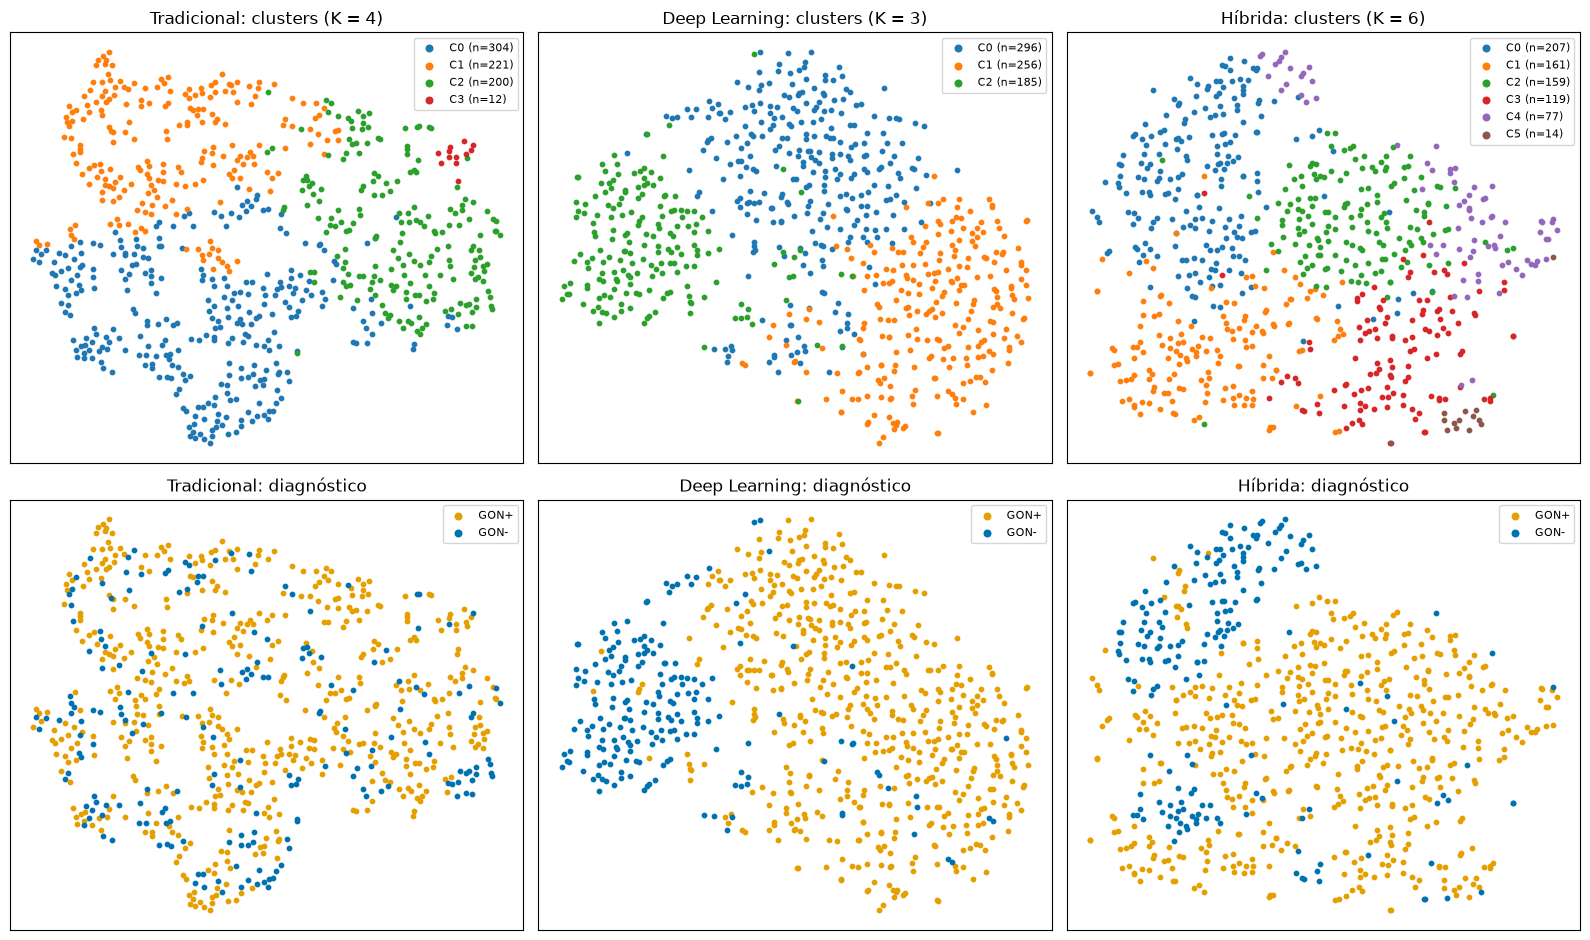

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for coluna, ab in enumerate(ABORDAGENS):
    xy = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(P[ab])
    k = K_ESCOLHIDO[ab]
    l = ROTULOS[ab][k]
    for c in range(k):
        axes[0, coluna].scatter(*xy[l == c].T, s=10, color=plt.get_cmap("tab10")(c), label=f"C{c} (n={(l == c).sum()})")
    axes[0, coluna].set_title(f"{ab}: clusters (K = {k})")
    axes[0, coluna].legend(fontsize=8, markerscale=1.5)
    for rotulo, cor in {"GON+": "#E69F00", "GON-": "#0072B2"}.items():
        axes[1, coluna].scatter(*xy[(meta["Label"] == rotulo).to_numpy()].T, s=10, color=cor, label=rotulo)
    axes[1, coluna].set_title(f"{ab}: diagnóstico")
    axes[1, coluna].legend(fontsize=8, markerscale=1.5)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

> **Leitura:** na Tradicional, GON+ e GON- aparecem misturados. No Deep Learning, os GON- formam uma região própria (o C2). Na Híbrida, não há fronteiras nítidas. Em nenhum dos mapas existem "ilhas" separadas, o que confirma as silhouettes baixas.

## 9. Comparação e robustez

- **Concordância entre as abordagens (ARI):** elas agrupam pelo mesmo critério?
- **Robustez:** refazemos todo o pipeline (padronização, PCA e K-Means) sem os 11 PNG, sem o terço de pior qualidade e com 1 imagem por paciente. Comparamos com o agrupamento original nas mesmas imagens (ARI) e vemos se a relação com o diagnóstico (NMI) se mantém.

In [10]:
print("=== CONCORDÂNCIA ENTRE AS ABORDAGENS (ARI, cada uma no seu K) ===")
display(pd.DataFrame([[adjusted_rand_score(ROTULOS[a][K_ESCOLHIDO[a]], ROTULOS[b][K_ESCOLHIDO[b]]) for b in ABORDAGENS]
                      for a in ABORDAGENS], index=ABORDAGENS, columns=ABORDAGENS).round(3))

rng = np.random.default_rng(SEED)
CENARIOS = {
    "Sem os 11 PNG": np.where(meta["is_png"] == 0)[0],
    "Sem o terço de pior qualidade": np.where(QUALIDADE >= np.quantile(QUALIDADE, 1 / 3))[0],
    "1 imagem por paciente": np.sort([rng.choice(np.where(IDX_PAC == p)[0]) for p in range(N_PAC)]),
}
linhas = []
for nome, idx in CENARIOS.items():
    linha = {"cenário": nome, "n": len(idx)}
    for ab in ABORDAGENS:
        k = K_ESCOLHIDO[ab]
        novo = ordenar_por_tamanho(KMeans(k, n_init=20, random_state=SEED).fit_predict(construir_P(ab, idx)))
        linha[f"ARI {ab}"] = adjusted_rand_score(ROTULOS[ab][k][idx], novo)
        linha[f"NMI {ab}"] = normalized_mutual_info_score(Y[idx], novo)
    linhas.append(linha)
print("=== ROBUSTEZ (ARI com o original e NMI com o diagnóstico) ===")
display(pd.DataFrame(linhas).set_index("cenário").round(3))

=== CONCORDÂNCIA ENTRE AS ABORDAGENS (ARI, cada uma no seu K) ===


,Tradicional,Deep Learning,Híbrida
Tradicional,1.000,0.027,0.436
Deep Learning,0.027,1.000,0.242
Híbrida,0.436,0.242,1.000


=== ROBUSTEZ (ARI com o original e NMI com o diagnóstico) ===


,n,ARI Tradicional,NMI Tradicional,ARI Deep Learning,NMI Deep Learning,ARI Híbrida,NMI Híbrida
cenário,,,,,,,
Sem os 11 PNG,726,0.980,0.006,0.955,0.346,0.969,0.076
Sem o terço de pior qualidade,492,0.758,0.005,0.588,0.370,0.619,0.181
1 imagem por paciente,283,0.869,0.023,0.874,0.317,0.630,0.122


> **Leitura:**
> - **Tradicional x Deep Learning quase não concordam** (ARI ≈ 0,03): agrupam por critérios diferentes (brilho/nitidez x padrão aprendido pela rede). A Híbrida fica entre as duas, mais perto da Tradicional.
> - **Sem os PNG**, os clusters quase não mudam (ARI ≥ 0,95): os PNG não sustentam o agrupamento.
> - **Sem as piores imagens** e **com 1 imagem por paciente**, a relação do Deep Learning com o diagnóstico se mantém (NMI entre 0,32 e 0,37). No notebook completo, o mesmo padrão aparece com EfficientNet-B0 e ResNet18.
>
> O resultado do Deep Learning é **robusto**, mas robusto não quer dizer clínico: um viés de origem também seria robusto.

## 10. Conclusões

1. **As imagens formam um contínuo, não grupos bem separados:** silhouette baixa e nenhum cotovelo.
2. **Cada abordagem enxerga algo diferente:**
   - *Tradicional:* brilho e nitidez da foto, sem relação com o diagnóstico (NMI ≈ 0,01).
   - *Deep Learning:* um grupo com quase todos os GON- e dois grupos de GON+ separados por qualidade (NMI 0,37).
   - *Híbrida:* mistura os dois efeitos.
3. **O resultado do Deep Learning é robusto** a PNG, qualidade, repetição de pacientes e troca de rede.
4. **O que não dá para afirmar:** que os clusters representam diagnóstico, estágio ou gravidade. O diagnóstico anda junto com ID, formato e largura das imagens, então os clusters podem refletir **origem** e **qualidade** das fotos.

**Resposta curta:** há estrutura real nas imagens, mas ela é explicada principalmente por qualidade, iluminação e origem. Não há evidência de subgrupos clínicos de glaucoma.

### Limitações
- 737 imagens de 283 pacientes; diagnóstico misturado com a origem das imagens.
- A rede foi treinada no ImageNet e nunca viu retinas: capta cor, brilho e textura.
- O K-Means assume grupos compactos e de tamanho parecido.

### Próximos passos
- Extrator pré-treinado em retinas (por exemplo RETFound).
- Testar CLAHE e recorte do campo de visão como estudo de ablação.
- Outros algoritmos de agrupamento (GMM, HDBSCAN) e UMAP.